# Backtest 2 · Forex PCA residual strategy on hourly bars (8 crosses)

Universe: 9 currencies + gold + silver (value in USD). Model refit every 24 hours on 480 hours, 3 factors removed. Traded crosses: AUDNZD, EURGBP, EURCHF, AUDCAD, NZDCAD, CADCHF, EURNOK, EURSEK. First with assumed spreads, then with **Vantage's recorded per-bar spreads**.

In [1]:
import sys
sys.path.insert(0, "../src")   # shared code lives in src/; data in ../data (see README)
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

In [2]:
%run ../src/fx_pca_strategy.py

Data: 2010-01-03 -> 2026-10-16, 98,486 hourly bars, 11 assets

PCA loadings, full sample (first 4 factors):
      EUR   GBP   AUD   NZD   CAD   CHF   JPY   NOK   SEK   XAU   XAG
PC1  0.36  0.31  0.35  0.34  0.30  0.29  0.17  0.34  0.35  0.23  0.23
PC2  0.12  0.14  0.13  0.11  0.17 -0.04 -0.29  0.19  0.18 -0.64 -0.59
PC3  0.25  0.06 -0.30 -0.25 -0.34  0.46  0.58  0.01  0.13 -0.13 -0.28
PC4  0.24  0.03 -0.33 -0.41 -0.21  0.11 -0.60  0.29  0.33  0.11  0.21
variance explained: [0.494 0.127 0.101 0.069 0.048 0.043] cumulative 3: 0.722



Variance ratio of each cross's PCA residual (out-of-sample), <1 = mean-reverting, >1 = trending


        resid 4h  resid 24h  resid 72h  resid 120h  resid 240h  raw 24h  raw 120h
AUDNZD      0.92       0.90       0.88        0.86        0.80     0.85      0.83
EURGBP      0.95       0.97       0.92        0.92        0.76     0.98      0.91
EURCHF      1.00       1.02       1.06        0.76        0.74     1.00      1.03
AUDCAD      0.91       0.85       0.78        0.69        0.59     0.83      0.73
NZDCAD      0.91       0.84       0.75        0.73        0.70     0.82      0.75
CADCHF      0.96       0.93       0.92        0.75        0.77     0.93      0.90
EURNOK      0.90       0.88       0.86        0.79        0.75     0.89      0.76
EURSEK      0.87       0.82       0.79        0.70        0.57     0.83      0.70



=== Portfolio backtest, all 8 crosses, Params(window=480, step=24, k=3, entry=2.0, exit=0.5, stop=4.0, max_hl=48.0, max_hold=96, target_vol=0.05, max_lev=30.0, spread_mult=1.0, real_spreads=False, bars_per_year=5900, vol_lookback=480) ===
CAGR %                   -1.252
Sharpe                   -0.142
Sharpe before costs       0.602
max DD %                -25.285
trades                 3896.000
trades/month             19.450
win %                    58.214
avg hold (h)             37.529
avg gross/trade %         0.018
avg cost/trade %          0.023

per cross:
        trades  win %  net total %  gross total %  Sharpe
AUDNZD   418.0  57.18        -7.51           0.82   -0.20
EURGBP   417.0  57.31        -7.77          -1.66   -0.22
EURCHF   543.0  58.38        -6.83          11.21   -0.17
AUDCAD   531.0  62.34        12.80          20.58    0.34
NZDCAD   499.0  59.12        -1.59           7.17   -0.04
CADCHF   498.0  51.61       -14.73          -5.40   -0.38
EURNOK   461.0  58.35 

  no costs             Sharpe   0.44  (before costs  0.60)  CAGR   2.92%  maxDD -15.44%  trades 3896


  spreads x2           Sharpe  -0.73  (before costs  0.60)  CAGR  -5.26%  maxDD -61.00%  trades 3896


... (6 outputs left out)

  max half-life 24h    Sharpe  -0.14  (before costs  0.54)  CAGR  -0.73%  maxDD -19.35%  trades 2138

=== Prop challenge (+8% target, 5% daily, 10% max loss, 120 days) ===


  risk x1: 844 attempts | unfinished 93% | fail: max loss 4% | pass 3% | median days to pass 99


  risk x2: 845 attempts | unfinished 39% | pass 28% | fail: max loss 25% | fail: daily loss 8% | median days to pass 57


  risk x4: 855 attempts | pass 42% | fail: daily loss 39% | fail: max loss 20% | unfinished 0% | median days to pass 22


In [3]:
%run ../src/compare_spreads.py

spread paid at trade times vs typical (median, % of price):
           AUDNZD  EURGBP  EURCHF  AUDCAD  NZDCAD  CADCHF  EURNOK  EURSEK
typical    0.0137  0.0151  0.0149  0.0181  0.0206  0.0243  0.0237   0.022
at trades  0.0137  0.0151  0.0149  0.0181  0.0206  0.0243  0.0237   0.022

                         assumed spreads    Vantage spreads
  Sharpe                          -0.142             -0.059
  Sharpe before costs              0.602              0.602
  CAGR %                          -1.252             -0.667
  max DD %                       -25.285            -22.813
  trades                        3896.000           3896.000
  win %                           58.214             58.470
  avg gross/trade %                0.018              0.018
  avg cost/trade %                 0.023              0.020

per cross with Vantage spreads:
        trades  win %  net total %  gross total %  cost total %  Sharpe
AUDNZD   418.0  57.18        -6.06           0.82          6.87   -0.16


  risk x1: unfinished 93% | fail: max loss 4% | pass 4%


  risk x2: unfinished 40% | pass 30% | fail: max loss 23% | fail: daily loss 8%


  risk x4: pass 44% | fail: daily loss 36% | fail: max loss 19% | unfinished 0%


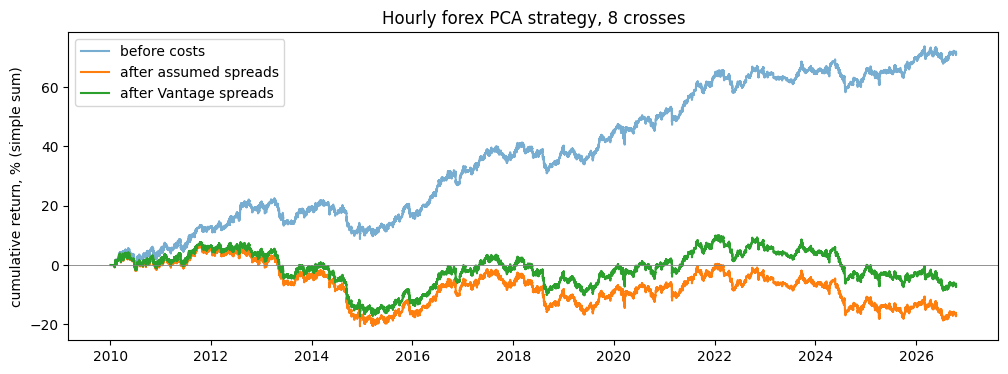

In [4]:
a = pd.read_csv("../data/backtest_fx/equity.csv", index_col=0, parse_dates=True)
r = pd.read_csv("../data/backtest_fx/equity_real_spreads.csv", index_col=0, parse_dates=True)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(a.index, a["gross"].cumsum() * 100, label="before costs", alpha=0.6)
ax.plot(a.index, a["ret"].cumsum() * 100, label="after assumed spreads")
ax.plot(r.index, r["ret"].cumsum() * 100, label="after Vantage spreads")
ax.axhline(0, color="grey", lw=0.6)
ax.set_ylabel("cumulative return, % (simple sum)")
ax.set_title("Hourly forex PCA strategy, 8 crosses")
ax.legend()
plt.show()

**Result:** there is an edge before costs (Sharpe ≈ +0.6), but hourly trades are too small to survive spreads and commission. This is why the strategy moves to daily candles (`backtesting/04`).